In [268]:
import importlib
import velocity_model
import torch
from matplotlib import pyplot

L = 5e6
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6])
h_tgrid = torch.linspace(0, 1.1, steps=11)
g_xranges_l = torch.tensor([1e6, 4.5e6])
g_xranges_u = torch.tensor([1.1e6, 4.6e6])

In [269]:
importlib.reload(velocity_model)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)

m.h_log = torch.nn.Parameter(torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1])))
m.g_log = torch.nn.Parameter(torch.log(torch.tensor([10,0.1])))

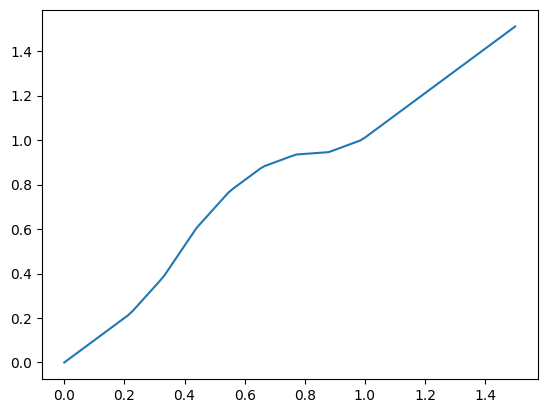

In [270]:
t = torch.linspace(0, 1.5, steps=100)
pyplot.plot(t, m.H(t).detach().numpy())


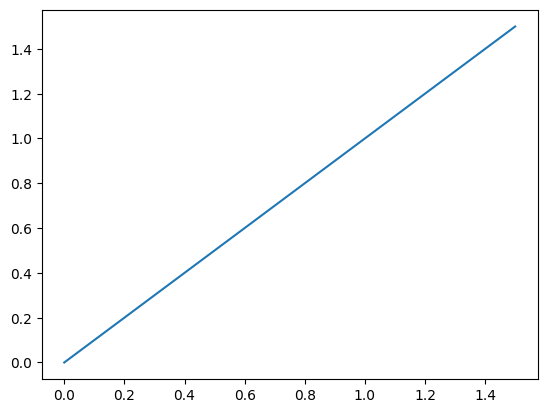

In [271]:
t = torch.linspace(0, 1.5, steps=100)
pyplot.plot(t, m.Hinv(m.H(t)).detach().numpy())

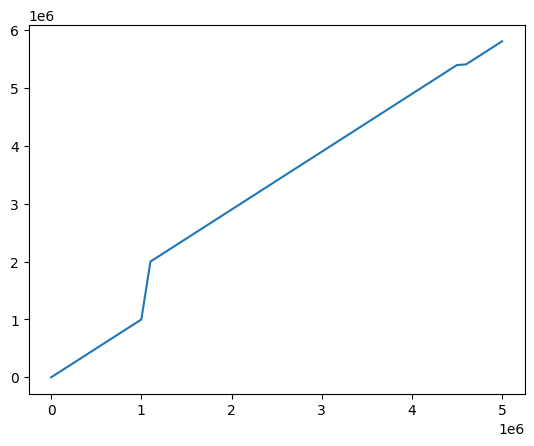

In [272]:
x = torch.linspace(0, L, steps=1000)
pyplot.plot(x, m.G_0(x).detach().numpy())

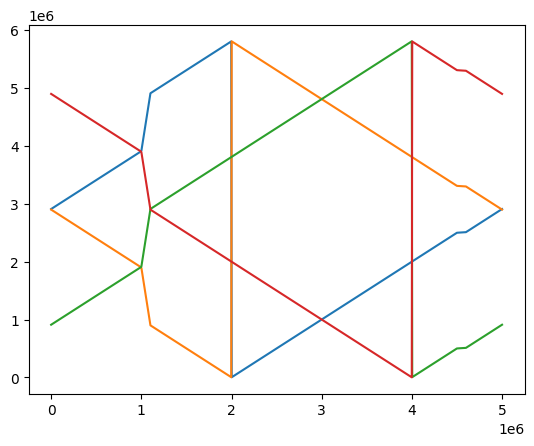

In [273]:
g1f = m.G(x, m.origins[0], torch.tensor([+1.0])).detach().numpy()
g1r = m.G(x, m.origins[0], torch.tensor([-1.0])).detach().numpy()
g2f = m.G(x, m.origins[1], torch.tensor([+1.0])).detach().numpy()
g2r = m.G(x, m.origins[1], torch.tensor([-1.0])).detach().numpy()
pyplot.plot(x, g1f, label="origin 1 fwd")
pyplot.plot(x, g1r, label="origin 1 rev")
pyplot.plot(x, g2f, label="origin 2 fwd")
pyplot.plot(x, g2r, label="origin 2 rev")

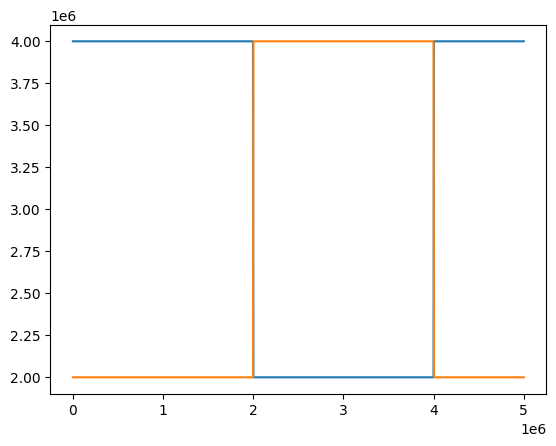

In [274]:
(i_l, i_r) = m.surrounding_origins(x)
pyplot.plot(x, m.origins[i_l], label="left")
pyplot.plot(x, m.origins[i_r], label="right")

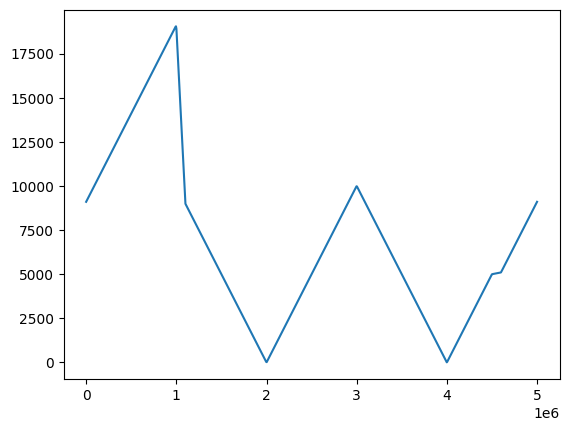

In [275]:
t = m.T(x).detach().numpy()
pyplot.plot(x, t)

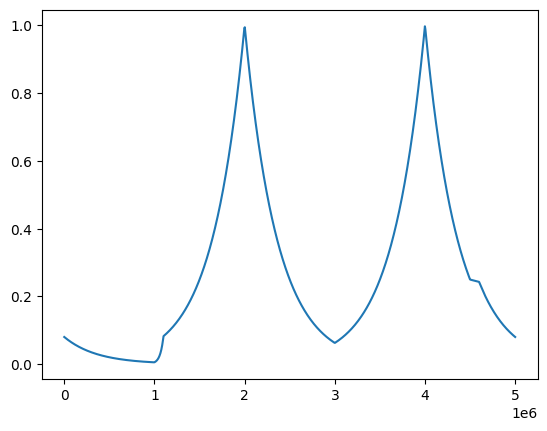

In [276]:
p = m.P(x).detach().numpy()
pyplot.plot(x, p)